<a href="https://colab.research.google.com/github/Dzikriyah/2418048_DataVisualization/blob/main/DataVisualization2418048.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **1. IMPORT LIBRARY**

Kode tersebut berfungsi untuk mengimpor pustaka penting seperti Pandas, NumPy, Matplotlib, dan Seaborn, lalu mengatur tampilan agar seluruh kolom tabel dan angka desimal (dua digit di belakang koma) dapat terbaca dengan jelas, serta mempercantik visualisasi grafik agar lebih tajam dan profesional

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur agar semua kolom tabel ditampilkan dan angka desimal dibatasi 2 angka
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Mengatur tampilan dasar grafik
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110

Untuk menghubungkan (mount) Google Drive ke Google Colab

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **2. LOAD DATASET**

Kode tersebut berfungsi untuk membaca file Excel (.xlsx) dari Google Drive, menyalinnya ke dalam variabel dataframe (df), lalu menampilkan ringkasan informasi dasar terkait dataset tersebut yang meliputi:

* Total jumlah baris dan kolom.

* Total keseluruhan data yang kosong (missing values).

* Total data yang bernilai sama persis atau duplikat.

* 5 baris pertama isi data secara visual dalam bentuk tabel.

In [ ]:
# Baca file .xlsx
file_path = '/content/drive/MyDrive/KULIAH DAN RANDOM/DATA MINING/T2/Dairy_Dataset_Visualization.xlsx'
df_raw = pd.read_excel(file_path, engine='openpyxl')  # Gunakan openpyxl untuk file .xlsx

df = df_raw.copy()

print(f"Jumlah Baris dan Kolom : {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Jumlah Data Kosong     : {df.isnull().sum().sum()}")
print(f"Jumlah Data Duplikat   : {df.duplicated().sum()}")

# Menampilkan 5 baris pertama data
display(df.head())

Jumlah Baris dan Kolom : 4325 baris, 23 kolom
Jumlah Data Kosong     : 0
Jumlah Data Duplikat   : 0


,Location,Total Land Area (acres),Number of Cows,Farm Size,Date,Product ID,Product Name,Brand,Quantity (liters/kg),Price per Unit,Total Value,Shelf Life (days),Storage Condition,Production Date,Expiration Date,Quantity Sold (liters/kg),Price per Unit (sold),Approx. Total Revenue(INR),Customer Location,Sales Channel,Quantity in Stock (liters/kg),Minimum Stock Threshold (liters/kg),Reorder Quantity (liters/kg)
0,Telangana,310.84,96,Medium,2022-02-17,5,Ice Cream,Dodla Dairy,222.40,85.72,19064.13,25,Frozen,2021-12-27,2022-01-21,7,82.24,575.68,Madhya Pradesh,Wholesale,215,19.55,64.03
1,Uttar Pradesh,19.19,44,Large,2021-12-01,1,Milk,Amul,687.48,42.61,29293.52,22,Tetra Pack,2021-10-03,2021-10-25,558,39.24,21895.92,Kerala,Wholesale,129,43.17,181.10
2,Tamil Nadu,581.69,24,Medium,2022-02-28,4,Yogurt,Dodla Dairy,503.48,36.50,18377.02,30,Refrigerated,2022-01-14,2022-02-13,256,33.81,8655.36,Madhya Pradesh,Online,247,15.10,140.83
3,Telangana,908.00,89,Small,2019-06-09,3,Cheese,Britannia Industries,823.36,26.52,21835.51,72,Frozen,2019-05-15,2019-07-26,601,28.92,17380.92,Rajasthan,Online,222,74.50,57.68
4,Maharashtra,861.95,21,Medium,2020-12-14,8,Buttermilk,Mother Dairy,147.77,83.85,12390.51,11,Refrigerated,2020-10-17,2020-10-28,145,83.07,12045.15,Jharkhand,Retail,2,76.02,33.40


### **3. Merapikan Nama Kolom, Teks, dan Product ID**

1. Mengubah beberapa nama kolom harga dan pendapatan supaya lebih mudah dibaca.
2. Menghapus spasi berlebih pada kolom teks.
3. Mengubah Product ID dari angka (1, 2, 3) menjadi kode teks (P01, P02, P03) supaya tidak ikut terhitung sebagai angka saat membuat grafik.

In [ ]:
# 1. Merapikan nama kolom harga dan pendapatan
rename_map = {
    'Approx. Total Revenue(INR)': 'Total Revenue (INR)',
    'Price per Unit': 'Base Price per Unit (INR)',
    'Price per Unit (sold)': 'Selling Price per Unit (INR)',
    'Total Value': 'Total Production Value (INR)'
}
df.rename(columns=rename_map, inplace=True)

# 2. Menghapus spasi berlebih pada kolom teks
str_cols = df.select_dtypes(include='object').columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip()

# 3. Mengubah Product ID menjadi format P01 - P10
df['Product ID'] = df_raw['Product ID'].apply(lambda x: f"P{int(x):02d}")

# Menampilkan contoh hasil perubahan
display(df[['Product ID', 'Product Name', 'Base Price per Unit (INR)', 'Selling Price per Unit (INR)', 'Total Revenue (INR)']].head())

,Product ID,Product Name,Base Price per Unit (INR),Selling Price per Unit (INR),Total Revenue (INR)
0,P05,Ice Cream,85.72,82.24,575.68
1,P01,Milk,42.61,39.24,21895.92
2,P04,Yogurt,36.50,33.81,8655.36
3,P03,Cheese,26.52,28.92,17380.92
4,P08,Buttermilk,83.85,83.07,12045.15


### **4. Memperbaiki Kategori Ukuran Peternakan**

Pada data awal, kategori ukuran peternakan (Small, Medium, Large) tidak sesuai dengan luas lahannya. Oleh karena itu, kategori Farm Size diperbaiki berdasarkan luas lahan :

1. Small: kurang dari 333,33 acres
2. Medium: 333,33 sampai 666,67 acres
3. Large: lebih dari 666,67 acres

In [ ]:
# Menyimpan data Farm Size asli untuk perbandingan
df['Farm Size (Original)'] = df_raw['Farm Size']

# Mengelompokkan ulang Farm Size berdasarkan luas lahan
df['Farm Size'] = pd.cut(
    df['Total Land Area (acres)'],
    bins=[0, 333.33, 666.67, np.inf],
    labels=['Small', 'Medium', 'Large']
).astype(str)

print("Jumlah data per kategori Farm Size setelah diperbaiki:")
print(df['Farm Size'].value_counts())

Jumlah data per kategori Farm Size setelah diperbaiki:
Farm Size
Large     1454
Medium    1445
Small     1426
Name: count, dtype: int64


### **5. Memisahkan Satuan Produk & Menyamakan Kondisi Penyimpanan**

1. Membuat kolom baru Unit Type untuk membedakan produk cair yang menggunakan satuan Liters  dan produk padat yang menggunakan satuan Kg.
2. Merapikan kolom penyimpanan  ke dalam kolom Storage Temperature karena pada produk susu masih tertulis jenis kemasannya, bukan suhu penyimpanannya.

In [ ]:
# 1. Membedakan satuan Liters (cair) dan Kg (padat)
liquid_products = ['Milk', 'Buttermilk', 'Lassi']
df['Unit Type'] = np.where(df['Product Name'].isin(liquid_products), 'Liters', 'Kg')

# 2. Menyamakan istilah kondisi penyimpanan menjadi suhu penyimpanan
df['Storage Condition (Original)'] = df_raw['Storage Condition']
storage_map = {
    'Polythene Packet': 'Refrigerated',
    'Tetra Pack': 'Ambient'
}
df['Storage Temperature'] = df['Storage Condition (Original)'].replace(storage_map)

print("Hasil pengelompokan satuan dan suhu penyimpanan:")
display(pd.crosstab(df['Product Name'], [df['Unit Type'], df['Storage Temperature']]))

Hasil pengelompokan satuan dan suhu penyimpanan:


Unit Type                Kg                      Liters             
Storage Temperature Ambient Frozen Refrigerated Ambient Refrigerated
Product Name                                                        
Butter                    0    226          205       0            0
Buttermilk                0      0            0       0          435
Cheese                    0    182          219       0            0
Curd                      0      0          479       0            0
Ghee                    402      0            0       0            0
Ice Cream                 0    423            0       0            0
Lassi                     0      0            0       0          447
Milk                      0      0            0     204          225
Paneer                    0      0          441       0            0
Yogurt                    0    204          233       0            0

### **6. Mengecek Tanggal Kedaluwarsa Produk**

Setelah dicek, banyak data transaksi yang tanggal pencatatannya sudah melewati tanggal kedaluwarsa. Di sini kita membuat kolom Expiration Status untuk menandai mana produk yang masih segar dan mana yang sudah lewat tanggal kedaluwarsa.

In [ ]:
# Memastikan kolom tanggal memiliki tipe data datetime
date_cols = ['Date', 'Production Date', 'Expiration Date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col])

# Menghitung sisa hari sebelum kedaluwarsa saat transaksi tercatat
df['Remaining Shelf Life (days)'] = (df['Expiration Date'] - df['Date']).dt.days

# Menandai status produk apakah masih segar atau sudah expired
df['Expiration Status'] = np.where(
    df['Date'] > df['Expiration Date'],
    'Expired at Transaction',
    'Valid / Fresh'
)

print("Jumlah transaksi berdasarkan status kedaluwarsa:")
print(df['Expiration Status'].value_counts())

Jumlah transaksi berdasarkan status kedaluwarsa:
Expiration Status
Expired at Transaction    2564
Valid / Fresh             1761
Name: count, dtype: int64


### **7. Memperbaiki Hitungan Stok, Pembulatan Harga, dan Selisih Harga**

1. Menghitung ulang kolom sisa stok dengan rumus Quantity - Quantity Sold agar jumlahnya pas dan angka desimalnya tidak hilang.
2. Membulatkan angka harga dan pendapatan menjadi 2 angka di belakang koma.
3. Menghitung selisih antara harga jual dan harga dasar  untuk mengetahui transaksi mana yang untung dan rugi/diskon .

In [ ]:
# 1. Menghitung ulang sisa stok agar sesuai dengan jumlah produksi dikurangi jumlah terjual
df['Quantity in Stock (liters/kg)'] = (
    df['Quantity (liters/kg)'] - df['Quantity Sold (liters/kg)']
).round(2)

# 2. Membulatkan kolom harga dan total nilai uang menjadi 2 angka di belakang koma
df['Base Price per Unit (INR)'] = df['Base Price per Unit (INR)'].round(2)
df['Selling Price per Unit (INR)'] = df['Selling Price per Unit (INR)'].round(2)
df['Total Production Value (INR)'] = (
    df['Quantity (liters/kg)'] * df['Base Price per Unit (INR)']
).round(2)
df['Total Revenue (INR)'] = (
    df['Quantity Sold (liters/kg)'] * df['Selling Price per Unit (INR)']
).round(2)

# 3. Menghitung selisih harga jual dengan harga dasar
df['Unit Price Margin (INR)'] = (
    df['Selling Price per Unit (INR)'] - df['Base Price per Unit (INR)']
).round(2)

df['Pricing Status'] = np.where(
    df['Unit Price Margin (INR)'] > 0, 'Profit / Markup',
    np.where(df['Unit Price Margin (INR)'] < 0, 'Loss / Markdown', 'Break-even')
)

print("Ringkasan status harga jual (Untung vs Rugi/Diskon):")
print(df['Pricing Status'].value_counts())

Ringkasan status harga jual (Untung vs Rugi/Diskon):
Pricing Status
Loss / Markdown    2163
Profit / Markup    2158
Break-even            4
Name: count, dtype: int64


### **8. Menandai Status Stok Gudang & Jangkauan Pengiriman**

1. Membuat kolom Stock Status untuk menandai apakah sisa stok sudah berada di bawah batas minimum atau masih aman.
2. Membuat kolom Distribution Scope untuk membedakan penjualan di dalam wilayah yang sama atau dikirim ke luar wilayah.

In [ ]:
# 1. Menandai apakah stok perlu dipesan ulang (Need Reorder) atau masih aman (Safe Stock)
df['Stock Status'] = np.where(
    df['Quantity in Stock (liters/kg)'] <= df['Minimum Stock Threshold (liters/kg)'],
    'Need Reorder',
    'Safe Stock'
)

# 2. Mengisi jumlah Reorder hanya jika stok benar-benar di bawah batas minimum
df['Effective Reorder Quantity (liters/kg)'] = np.where(
    df['Stock Status'] == 'Need Reorder',
    df['Reorder Quantity (liters/kg)'],
    0.0
).round(2)

# 3. Menandai jangkauan pengiriman (Lokal vs Antar Negara Bagian)
df['Distribution Scope'] = np.where(
    df['Location'] == df['Customer Location'],
    'Local (Same State)',
    'Inter-State'
)

print("Status ketersediaan stok di gudang:")
print(df['Stock Status'].value_counts())

Status ketersediaan stok di gudang:
Stock Status
Safe Stock      3414
Need Reorder     911
Name: count, dtype: int64


### **9. Ringkasan Statistik Data Setelah Dibersihkan**

Kode tersebut digunakan untuk menghitung, merapikan, dan menampilkan tabel ringkasan statistik deskriptif dari kolom-kolom angka yang ada di dalam dataset.

In [ ]:
# Memilih kolom angka utama untuk dicek statistiknya
kolom_angka = [
    'Total Land Area (acres)', 'Number of Cows', 'Quantity (liters/kg)',
    'Base Price per Unit (INR)', 'Total Production Value (INR)', 'Shelf Life (days)',
    'Quantity Sold (liters/kg)', 'Selling Price per Unit (INR)', 'Total Revenue (INR)',
    'Quantity in Stock (liters/kg)', 'Minimum Stock Threshold (liters/kg)',
    'Effective Reorder Quantity (liters/kg)', 'Unit Price Margin (INR)', 'Remaining Shelf Life (days)'
]

# Menampilkan tabel statistik deskriptif
statistik_data = df[kolom_angka].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']]
statistik_data.rename(columns={'50%': 'median'}, inplace=True)
display(statistik_data)

,count,mean,median,std,min,max
Total Land Area (acres),4325.00,503.48,509.17,285.94,10.17,999.53
Number of Cows,4325.00,54.96,55.00,26.11,10.00,100.00
Quantity (liters/kg),4325.00,500.65,497.55,288.98,1.17,999.93
Base Price per Unit (INR),4325.00,54.79,54.40,26.00,10.03,99.99
Total Production Value (INR),4325.00,27357.85,21869.65,21621.05,42.52,99036.37
Shelf Life (days),4325.00,29.13,22.00,30.27,1.00,150.00
Quantity Sold (liters/kg),4325.00,248.10,189.00,217.02,1.00,960.00
Selling Price per Unit (INR),4325.00,54.78,54.14,26.19,5.21,104.51
Total Revenue (INR),4325.00,13580.27,8394.54,14617.01,12.54,89108.90
Quantity in Stock (liters/kg),4325.00,252.56,191.45,223.62,0.17,976.15


### **10. Visualisasi 1 — Perbandingan Farm Size Sebelum dan Sesudah Dibersihkan**

Grafik Boxplot di bawah ini membuktikan hasil perbaikan pada kolom Farm Size.

/tmp/ipykernel_1645/1671239520.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1645/1671239520.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


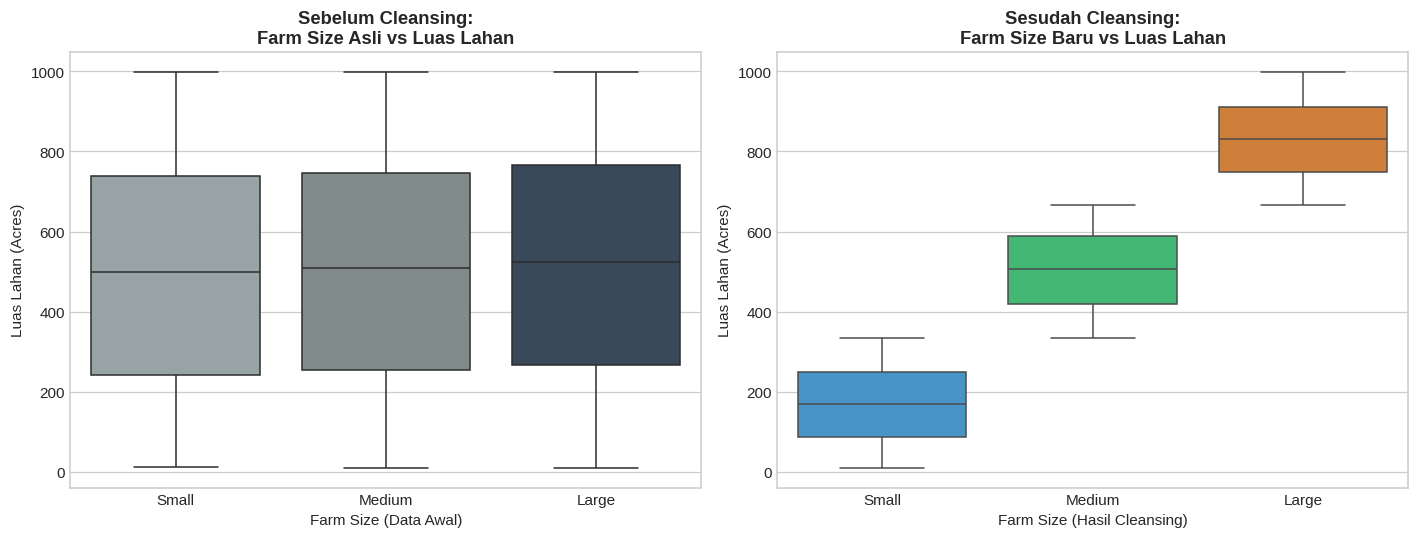

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik Sebelum Cleansing
sns.boxplot(
    data=df, x='Farm Size (Original)', y='Total Land Area (acres)',
    order=['Small', 'Medium', 'Large'], ax=axes[0], palette=['#95a5a6', '#7f8c8d', '#34495e']
)
axes[0].set_title('Sebelum Cleansing:\nFarm Size Asli vs Luas Lahan', fontweight='bold')
axes[0].set_xlabel('Farm Size (Data Awal)')
axes[0].set_ylabel('Luas Lahan (Acres)')

# Grafik Sesudah Cleansing
sns.boxplot(
    data=df, x='Farm Size', y='Total Land Area (acres)',
    order=['Small', 'Medium', 'Large'], ax=axes[1], palette=['#3498db', '#2ecc71', '#e67e22']
)
axes[1].set_title('Sesudah Cleansing:\nFarm Size Baru vs Luas Lahan', fontweight='bold')
axes[1].set_xlabel('Farm Size (Hasil Cleansing)')
axes[1].set_ylabel('Luas Lahan (Acres)')

plt.tight_layout()
plt.show()

### **11. Visualisasi 2: Jumlah Transaksi Produk Segar vs Kedaluwarsa**

Grafik ini menampilkan perbandingan jumlah transaksi yang masih segar dan yang sudah melewati masa simpan pada setiap produk.

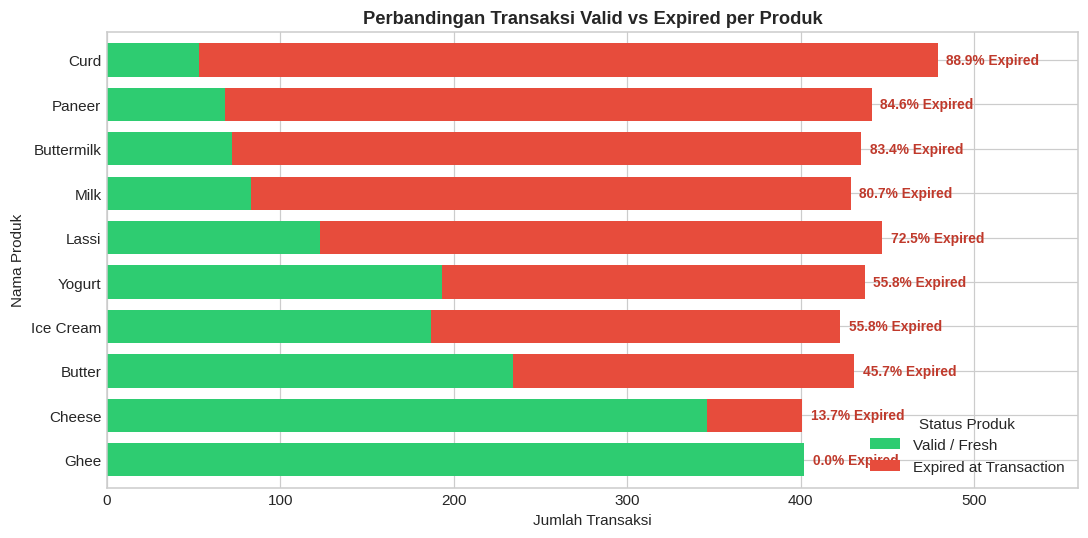

In [ ]:
exp_prod = pd.crosstab(df['Product Name'], df['Expiration Status'])
exp_prod['Total'] = exp_prod.sum(axis=1)
exp_prod = exp_prod.sort_values('Expired at Transaction', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
exp_prod[['Valid / Fresh', 'Expired at Transaction']].plot(
    kind='barh', stacked=True, ax=ax, color=['#2ecc71', '#e74c3c'], width=0.75
)

ax.set_title('Perbandingan Transaksi Valid vs Expired per Produk', fontweight='bold')
ax.set_xlabel('Jumlah Transaksi')
ax.set_ylabel('Nama Produk')
ax.legend(title='Status Produk', loc='lower right')

for i, (valid_v, exp_v, tot_v) in enumerate(zip(exp_prod['Valid / Fresh'], exp_prod['Expired at Transaction'], exp_prod['Total'])):
    pct_exp = (exp_v / tot_v) * 100
    ax.text(tot_v + 5, i, f"{pct_exp:.1f}% Expired", va='center', fontsize=9, fontweight='bold', color='#c0392b')

ax.set_xlim(0, 560)
plt.tight_layout()
plt.show()

### **12. Visualisasi 3: Total Pendapatan per Produk dan Tren Waktu**

1. Grafik Kiri: Menunjukkan total pendapatan untuk masing-masing produk. Jika hanya menghitung produk yang masih segar, pendapatan terbesar berasal dari Ghee, Cheese, dan Butter.
2. Grafik Kanan: Menunjukkan pergerakan pendapatan setiap kuartal dari tahun 2019 hingga 2022.

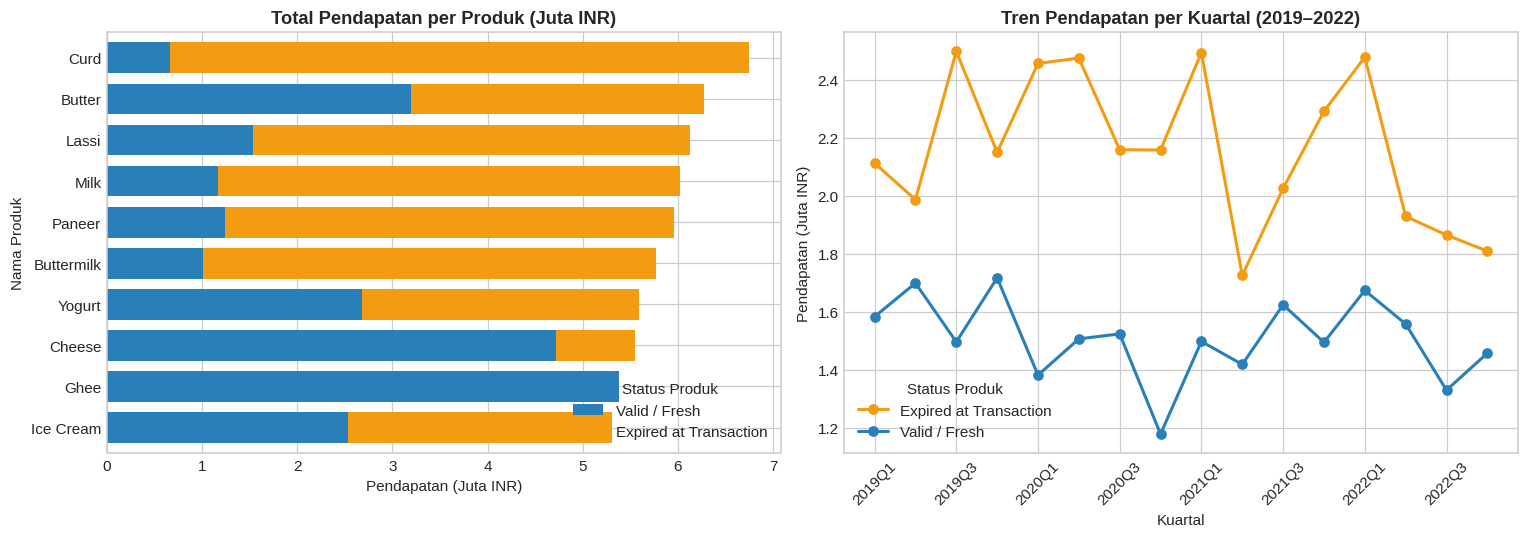

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Kiri: Total Revenue per Produk
rev_prod = df.groupby(['Product Name', 'Expiration Status'])['Total Revenue (INR)'].sum().unstack() / 1e6
rev_prod['Total'] = rev_prod.sum(axis=1)
rev_prod = rev_prod.sort_values('Total', ascending=True)

rev_prod[['Valid / Fresh', 'Expired at Transaction']].plot(
    kind='barh', stacked=True, ax=axes[0], color=['#2980b9', '#f39c12'], width=0.75
)
axes[0].set_title('Total Pendapatan per Produk (Juta INR)', fontweight='bold')
axes[0].set_xlabel('Pendapatan (Juta INR)')
axes[0].set_ylabel('Nama Produk')
axes[0].legend(title='Status Produk', loc='lower right')

# Grafik Kanan: Tren Pendapatan per Kuartal (2019 - 2022)
df['YearQuarter'] = df['Date'].dt.to_period('Q').astype(str)
trend_q = df.groupby(['YearQuarter', 'Expiration Status'])['Total Revenue (INR)'].sum().unstack() / 1e6

trend_q.plot(
    kind='line', marker='o', ax=axes[1],
    color={'Valid / Fresh': '#2980b9', 'Expired at Transaction': '#f39c12'}, linewidth=2
)
axes[1].set_title('Tren Pendapatan per Kuartal (2019–2022)', fontweight='bold')
axes[1].set_xlabel('Kuartal')
axes[1].set_ylabel('Pendapatan (Juta INR)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Status Produk')

plt.tight_layout()
plt.show()

### **13. Visualisasi 4: Volume Terjual vs Sisa Stok & Pendapatan per Lokasi**

1. Grafik Kiri: Menampilkan jumlah barang yang terjual dibandingkan sisa stok di gudang setelah dipisahkan satuannya antara Liters dan Kg.
2. Grafik Kanan: Menampilkan total pendapatan dari masing-masing lokasi peternakan dan saluran penjualannya. Lokasi dengan pendapatan tertinggi adalah Chandigarh dan Delhi.

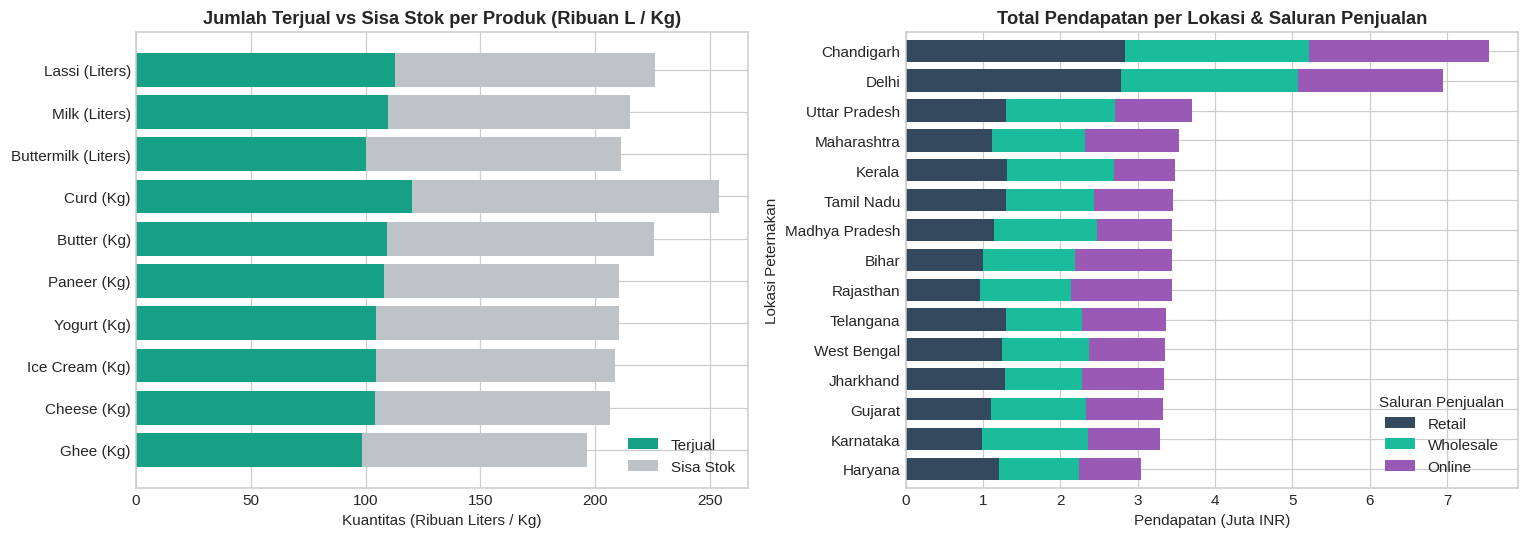

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Kiri: Volume Terjual vs Sisa Stok
vol_summary = df.groupby(['Unit Type', 'Product Name'])[['Quantity Sold (liters/kg)', 'Quantity in Stock (liters/kg)']].sum().reset_index()
vol_summary['Total'] = vol_summary['Quantity Sold (liters/kg)'] + vol_summary['Quantity in Stock (liters/kg)']
vol_summary = vol_summary.sort_values(['Unit Type', 'Total'], ascending=[True, True])

y_labels = [f"{r['Product Name']} ({r['Unit Type']})" for _, r in vol_summary.iterrows()]
axes[0].barh(y_labels, vol_summary['Quantity Sold (liters/kg)'] / 1e3, label='Terjual', color='#16a085')
axes[0].barh(
    y_labels, vol_summary['Quantity in Stock (liters/kg)'] / 1e3,
    left=vol_summary['Quantity Sold (liters/kg)'] / 1e3,
    label='Sisa Stok', color='#bdc3c7'
)
axes[0].set_title('Jumlah Terjual vs Sisa Stok per Produk (Ribuan L / Kg)', fontweight='bold')
axes[0].set_xlabel('Kuantitas (Ribuan Liters / Kg)')
axes[0].legend(loc='lower right')

# Grafik Kanan: Pendapatan per Lokasi & Saluran Penjualan
loc_channel = df.groupby(['Location', 'Sales Channel'])['Total Revenue (INR)'].sum().unstack() / 1e6
loc_channel['Total'] = loc_channel.sum(axis=1)
loc_channel = loc_channel.sort_values('Total', ascending=True)

loc_channel[['Retail', 'Wholesale', 'Online']].plot(
    kind='barh', stacked=True, ax=axes[1], color=['#34495e', '#1abc9c', '#9b59b6'], width=0.75
)
axes[1].set_title('Total Pendapatan per Lokasi & Saluran Penjualan', fontweight='bold')
axes[1].set_xlabel('Pendapatan (Juta INR)')
axes[1].set_ylabel('Lokasi Peternakan')
axes[1].legend(title='Saluran Penjualan', loc='lower right')

plt.tight_layout()
plt.show()

### **14. Visualisasi 5: Distribusi Selisih Harga Jual (Margin) & Kebutuhan Restock Produk**

Grafik Kiri: Menampilkan sebaran selisih harga jual dengan harga dasar
Grafik Kanan: Menampilkan jumlah kebutuhan pemesanan ulang

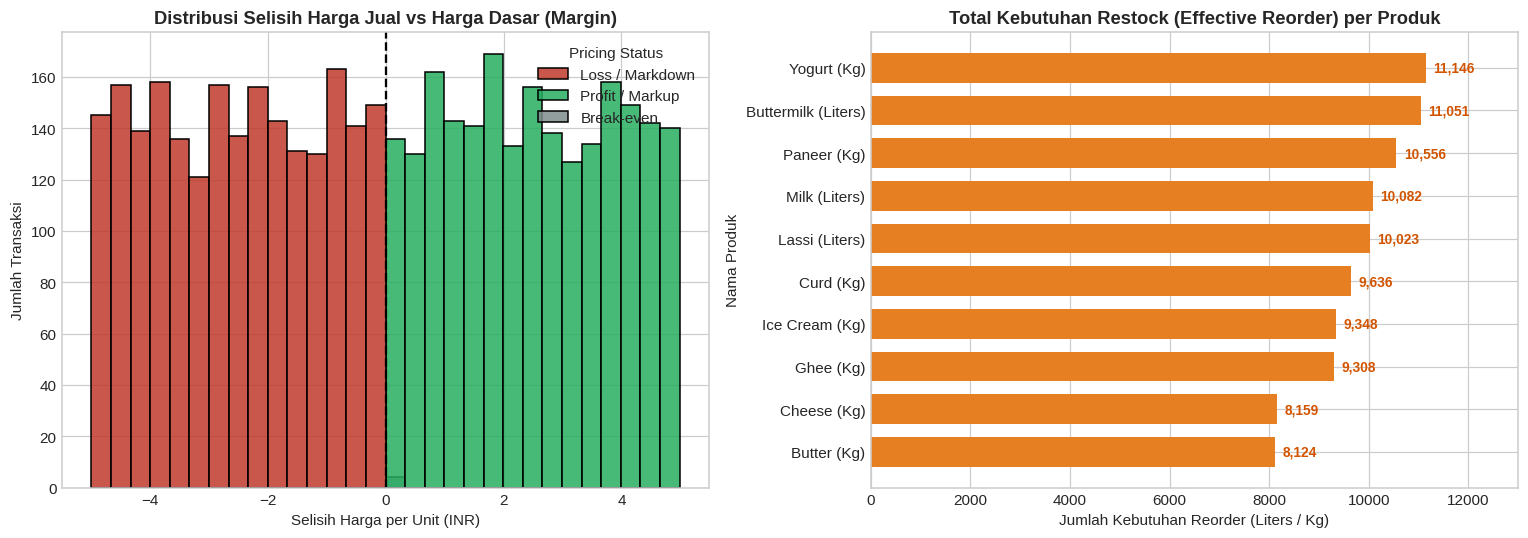

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Kiri: Distribusi Selisih Harga (Unit Price Margin)
sns.histplot(
    data=df, x='Unit Price Margin (INR)', hue='Pricing Status', bins=30, ax=axes[0],
    palette={'Profit / Markup': '#27ae60', 'Loss / Markdown': '#c0392b', 'Break-even': '#7f8c8d'}, alpha=0.85
)
axes[0].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('Distribusi Selisih Harga Jual vs Harga Dasar (Margin)', fontweight='bold')
axes[0].set_xlabel('Selisih Harga per Unit (INR)')
axes[0].set_ylabel('Jumlah Transaksi')

# Grafik Kanan: Jumlah Kebutuhan Reorder (Effective Reorder Quantity) per Produk
reorder_prod = df.groupby(['Product Name', 'Unit Type'])['Effective Reorder Quantity (liters/kg)'].sum().reset_index()
reorder_prod = reorder_prod.sort_values('Effective Reorder Quantity (liters/kg)', ascending=True)
y_labels_ro = [f"{r['Product Name']} ({r['Unit Type']})" for _, r in reorder_prod.iterrows()]

axes[1].barh(y_labels_ro, reorder_prod['Effective Reorder Quantity (liters/kg)'], color='#e67e22', height=0.7)
axes[1].set_title('Total Kebutuhan Restock (Effective Reorder) per Produk', fontweight='bold')
axes[1].set_xlabel('Jumlah Kebutuhan Reorder (Liters / Kg)')
axes[1].set_ylabel('Nama Produk')

for i, val in enumerate(reorder_prod['Effective Reorder Quantity (liters/kg)']):
    axes[1].text(val + 150, i, f"{val:,.0f}", va='center', fontsize=9, fontweight='bold', color='#d35400')
axes[1].set_xlim(0, 13000)

plt.tight_layout()
plt.show()

### **15. Visualisasi 6: Total Pendapatan per Merek (Brand) & Masa Simpan Berdasarkan Suhu Penyimpanan**

Grafik Kiri: Menampilkan peringkat merek (Brand) dengan pendapatan tertinggi.
Grafik Kanan: Menampilkan hubungan antara suhu penyimpanan dengan masa simpan.

/tmp/ipykernel_1645/2213012043.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


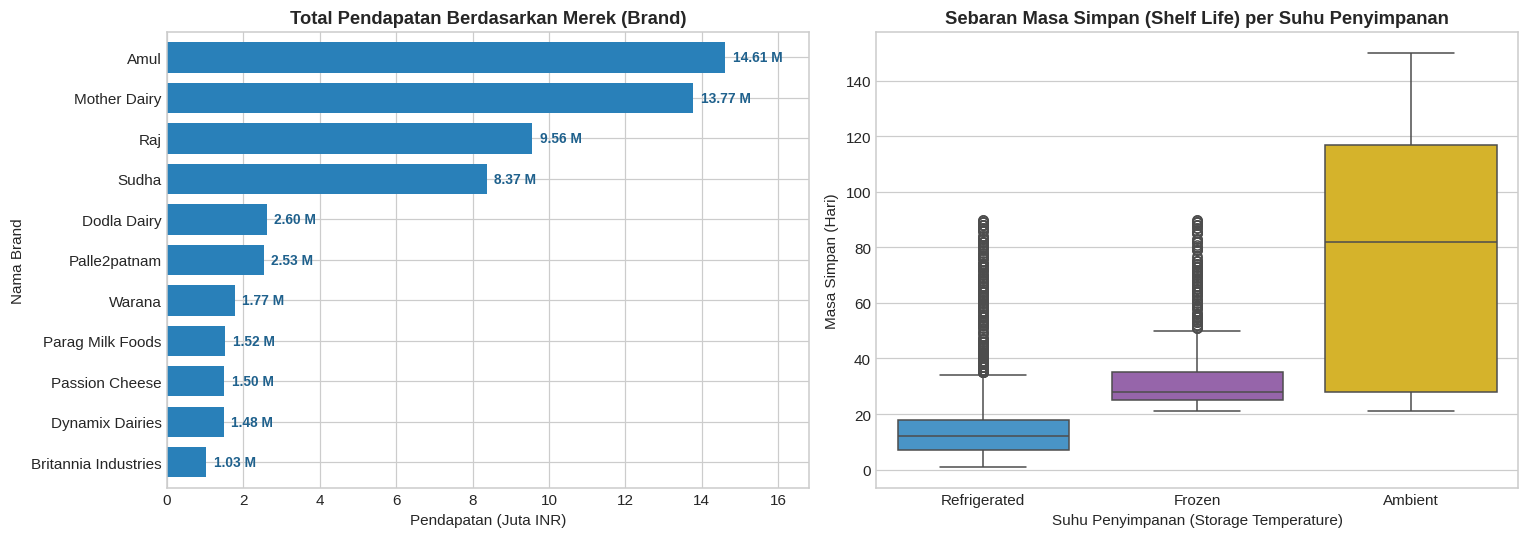

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Kiri: Total Pendapatan per Brand (Merek)
brand_rev = df.groupby('Brand')['Total Revenue (INR)'].sum().sort_values(ascending=True) / 1e6
brand_rev.plot(kind='barh', ax=axes[0], color='#2980b9', width=0.75)
axes[0].set_title('Total Pendapatan Berdasarkan Merek (Brand)', fontweight='bold')
axes[0].set_xlabel('Pendapatan (Juta INR)')
axes[0].set_ylabel('Nama Brand')

for i, val in enumerate(brand_rev):
    axes[0].text(val + 0.2, i, f"{val:.2f} M", va='center', fontsize=9, fontweight='bold', color='#1f618d')
axes[0].set_xlim(0, 16.8)

# Grafik Kanan: Masa Simpan (Shelf Life) Berdasarkan Suhu Penyimpanan
sns.boxplot(
    data=df, x='Storage Temperature', y='Shelf Life (days)',
    order=['Refrigerated', 'Frozen', 'Ambient'], ax=axes[1],
    palette=['#3498db', '#9b59b6', '#f1c40f']
)
axes[1].set_title('Sebaran Masa Simpan (Shelf Life) per Suhu Penyimpanan', fontweight='bold')
axes[1].set_xlabel('Suhu Penyimpanan (Storage Temperature)')
axes[1].set_ylabel('Masa Simpan (Hari)')

plt.tight_layout()
plt.show()

### **16. Menyimpan Dataset Hasil Cleansing**

Tahap terakhir adalah menyimpan data yang sudah selesai dibersihkan

In [ ]:
# 1. Memisahkan data khusus transaksi yang valid (belum kedaluwarsa) jika dibutuhkan
df_valid = df[df['Expiration Status'] == 'Valid / Fresh'].copy()

# 2. Menyimpan seluruh data yang sudah dibersihkan ke file CSV dan Excel
df.to_csv('dataset_visualisasi_cleaned.csv', index=False)
df.to_excel('dataset_visualisasi_cleaned.xlsx', index=False)

# 3. Menyimpan data khusus transaksi yang valid saja
df_valid.to_csv('dataset_visualisasi_valid_only.csv', index=False)

print("File berhasil disimpan! Silakan cek di menu Files (ikon folder) di sebelah kiri Colab.")

File berhasil disimpan! Silakan cek di menu Files (ikon folder) di sebelah kiri Colab.
